## Interval Analysis

In [11]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)

In [12]:
## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [13]:
## Network: 3 hidden layers of 50 neurons (Linear + ReLU), outputs raw logits.
## Normalization is the first layer, so eps is measured in pixel space.
class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307) / 0.3081

def make_net():
    return nn.Sequential(
        Normalize(),
        nn.Flatten(),
        nn.Linear(784, 50), nn.ReLU(),
        nn.Linear(50, 50), nn.ReLU(),
        nn.Linear(50, 50), nn.ReLU(),
        nn.Linear(50, 10),
    ).to(device)

In [18]:
def interval_forward(net, lo, hi):
    for layer in net:
        if isinstance(layer, nn.Linear):
            mid = layer((hi + lo) / 2)
            rad = ((hi - lo) / 2) @ layer.weight.abs().t()
            lo, hi = mid - rad, mid + rad
        else:  # Normalize, Flatten and ReLU are all monotone increasing
            lo, hi = layer(lo), layer(hi)
    return lo, hi

def worst_case_logits(net, x, y, eps):
    # IBP bounds up to the last hidden layer
    lo = (x - eps).clamp(0, 1)
    hi = (x + eps).clamp(0, 1)
    lo, hi = interval_forward(net[:-1], lo, hi)
    mid, rad = (hi + lo) / 2, (hi - lo) / 2

    # merge the last linear layer with the specification (Equation 9):
    # row j bounds z_j - z_y, so the true-class entry is exactly 0
    last = net[-1]
    W = last.weight.unsqueeze(0) - last.weight[y].unsqueeze(1)   # (batch, 10, 50)
    b = last.bias.unsqueeze(0) - last.bias[y].unsqueeze(1)        # (batch, 10)
    return (W @ mid.unsqueeze(2)).squeeze(2) + (W.abs() @ rad.unsqueeze(2)).squeeze(2) + b

def verify(net, x, y, eps):
    # HW2 box verifier: certified if the true logit's lower bound
    # beats every other logit's upper bound over the whole eps-ball
    with torch.no_grad():
        lo = (x - eps).clamp(0, 1)
        hi = (x + eps).clamp(0, 1)
        z_lo, z_hi = interval_forward(net, lo, hi)
        true_lo = z_lo.gather(1, y.unsqueeze(1)).squeeze(1)
        others_hi = z_hi.masked_fill(F.one_hot(y, 10).bool(), -float("inf"))
        return true_lo > others_hi.max(1).values

In [19]:
def schedule(step, warmup, rampup, eps_train=0.1, kappa_final=0.5):
    t = 0.0 if step < warmup else min(1.0, (step - warmup) / rampup)
    eps = t * eps_train
    kappa = 1.0 - t * (1.0 - kappa_final)
    return eps, kappa

def train(net, epochs, ibp=True):
    opt = torch.optim.Adam(net.parameters(), lr=1e-3)
    lr_sched = torch.optim.lr_scheduler.MultiStepLR(opt, milestones=[15], gamma=0.1)
    warmup, rampup = 1 * len(train_loader), 10 * len(train_loader)
    step = 0

    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.time()

    for epoch in range(epochs):
        net.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(net(x), y)
            if ibp:
                eps, kappa = schedule(step, warmup, rampup)
                spec_loss = F.cross_entropy(worst_case_logits(net, x, y, eps), y)
                loss = kappa * loss + (1 - kappa) * spec_loss
            opt.zero_grad()
            loss.backward()
            opt.step()
            step += 1
        lr_sched.step()
        print(f"epoch {epoch + 1}: loss {loss.item():.4f}")

    if device.type == "cuda":
        torch.cuda.synchronize()
    return time.time() - start

In [20]:
def pgd(net, x, y, eps, steps=40):
    alpha = 2.5 * eps / steps
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
    for _ in range(steps):
        x_adv.requires_grad_(True)
        loss = F.cross_entropy(net(x_adv), y)
        grad, = torch.autograd.grad(loss, x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps).clamp(0, 1)
    return x_adv.detach()

def evaluate(net, eps=0.1):
    net.eval()
    clean = robust = total = 0
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        with torch.no_grad():
            clean += (net(x).argmax(1) == y).sum().item()
        x_adv = pgd(net, x, y, eps)
        with torch.no_grad():
            robust += (net(x_adv).argmax(1) == y).sum().item()
        total += len(y)
    return 100 * clean / total, 100 * robust / total

In [21]:
EPOCHS = 20

std_net = make_net()
std_time = train(std_net, EPOCHS, ibp=False)

ibp_net = make_net()
ibp_time = train(ibp_net, EPOCHS, ibp=True)

for name, net, t in [("standard", std_net, std_time), ("IBP", ibp_net, ibp_time)]:
    clean, robust = evaluate(net, eps=0.1)
    print(f"{name}: clean acc {clean:.2f}%, PGD acc (eps=0.1) {robust:.2f}%, train time {t:.1f}s")
print(f"IBP / standard time ratio: {ibp_time / std_time:.2f}x")

epoch 1: loss 0.1403
epoch 2: loss 0.0388
epoch 3: loss 0.0768
epoch 4: loss 0.0220
epoch 5: loss 0.0211
epoch 6: loss 0.0462
epoch 7: loss 0.0028
epoch 8: loss 0.0579
epoch 9: loss 0.0162
epoch 10: loss 0.0444
epoch 11: loss 0.0215
epoch 12: loss 0.1049
epoch 13: loss 0.0244
epoch 14: loss 0.0026
epoch 15: loss 0.0013
epoch 16: loss 0.0028
epoch 17: loss 0.0148
epoch 18: loss 0.0014
epoch 19: loss 0.0231
epoch 20: loss 0.0054
epoch 1: loss 0.0202
epoch 2: loss 0.2822
epoch 3: loss 0.0855
epoch 4: loss 0.1726
epoch 5: loss 0.5005
epoch 6: loss 0.3756
epoch 7: loss 0.6201
epoch 8: loss 0.2353
epoch 9: loss 0.3448
epoch 10: loss 0.3541
epoch 11: loss 0.6756
epoch 12: loss 0.5129
epoch 13: loss 0.5520
epoch 14: loss 0.4197
epoch 15: loss 0.2566
epoch 16: loss 0.4539
epoch 17: loss 0.4827
epoch 18: loss 0.5281
epoch 19: loss 0.1995
epoch 20: loss 0.5384
standard: clean acc 97.86%, PGD acc (eps=0.1) 9.84%, train time 225.8s
IBP: clean acc 94.37%, PGD acc (eps=0.1) 85.40%, train time 277.5s


In [22]:
eps_values = [round(float(e), 2) for e in np.linspace(0.01, 0.1, 10)]
adv_examples = {}
ibp_net.eval()

for eps in eps_values:
    verified = attacked = total = 0
    found = []
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        cert = verify(ibp_net, x, y, eps)
        verified += cert.sum().item()

        not_cert = ~cert
        if not_cert.any():
            xs, ys = x[not_cert], y[not_cert]
            x_adv = pgd(ibp_net, xs, ys, eps)
            with torch.no_grad():
                pred = ibp_net(x_adv).argmax(1)
                clean_ok = ibp_net(xs).argmax(1) == ys
            hit = pred != ys
            attacked += hit.sum().item()
            keep = hit & clean_ok
            if len(found) < 10:
                found += list(zip(xs[keep], x_adv[keep], ys[keep], pred[keep]))
        total += len(y)

    adv_examples[eps] = found[:10]
    unknown = total - verified - attacked
    print(f"eps={eps:.2f}  verified {100 * verified / total:.2f}%  "
          f"attack found {100 * attacked / total:.2f}%  unknown {100 * unknown / total:.2f}%")

eps=0.01  verified 93.09%  attack found 6.24%  unknown 0.67%
eps=0.02  verified 91.45%  attack found 6.87%  unknown 1.68%
eps=0.03  verified 89.96%  attack found 7.41%  unknown 2.63%
eps=0.04  verified 87.83%  attack found 7.98%  unknown 4.19%
eps=0.05  verified 85.41%  attack found 8.87%  unknown 5.72%
eps=0.06  verified 82.72%  attack found 9.88%  unknown 7.40%
eps=0.07  verified 79.45%  attack found 10.95%  unknown 9.60%
eps=0.08  verified 75.14%  attack found 12.02%  unknown 12.84%
eps=0.09  verified 70.22%  attack found 13.18%  unknown 16.60%
eps=0.10  verified 65.11%  attack found 14.63%  unknown 20.26%


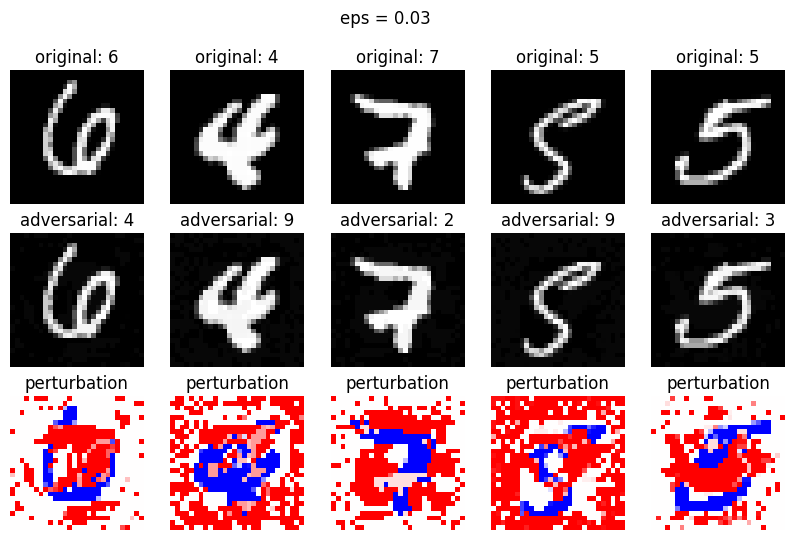

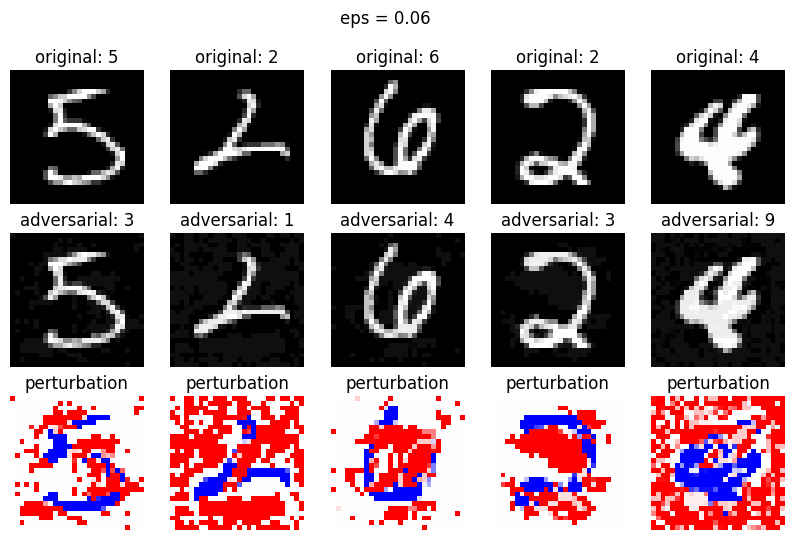

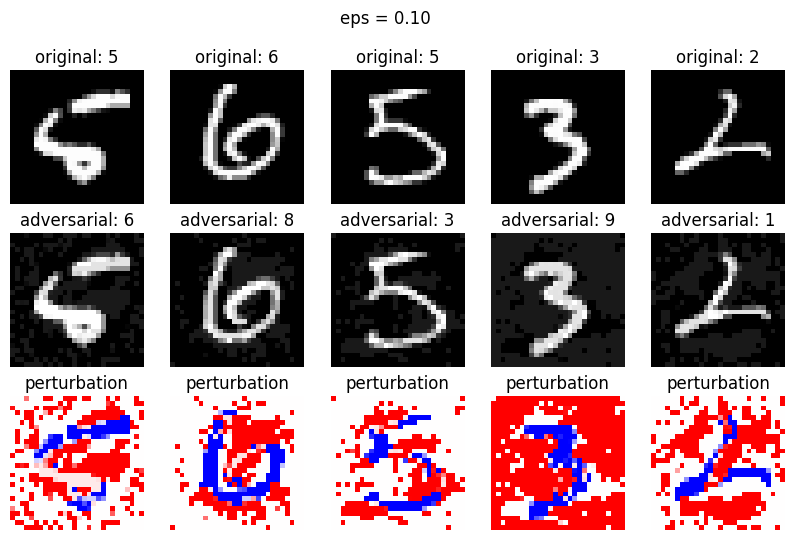

In [23]:
def show_adversarial(eps, n=5):
    examples = adv_examples[eps][:n]
    if not examples:
        print(f"no adversarial examples found at eps={eps:.2f}")
        return
    fig, axes = plt.subplots(3, len(examples), figsize=(2 * len(examples), 6), squeeze=False)
    for i, (x, x_adv, y, pred) in enumerate(examples):
        axes[0, i].imshow(x.squeeze().cpu(), cmap="gray")
        axes[0, i].set_title(f"original: {y.item()}")
        axes[1, i].imshow(x_adv.squeeze().cpu(), cmap="gray")
        axes[1, i].set_title(f"adversarial: {pred.item()}")
        axes[2, i].imshow((x_adv - x).squeeze().cpu(), cmap="bwr", vmin=-eps, vmax=eps)
        axes[2, i].set_title("perturbation")
    for ax in axes.flat:
        ax.axis("off")
    plt.suptitle(f"eps = {eps:.2f}")
    plt.show()

for eps in [eps_values[2], eps_values[5], eps_values[9]]:
    show_adversarial(eps)